# Churn Prediction — End-to-End Walkthrough (Reference Layout)

This notebook exercises every module in `src/` for real: raw data in,
a trained model and risk scores out. It's the notebook counterpart to the
standalone Week 1–4 scripts in the parent project — those are written to
be read top-to-bottom for a course deliverable; this is the same pipeline
called as an importable package instead.

For the fully tuned experiment (RandomizedSearchCV, calibration analysis,
permutation importance), see `Week3_ML_Model_Development/model_training_v2.py`
and `MODEL_CARD.md` in the project root — this notebook uses fixed
hyperparameters so it runs in seconds, not minutes.

In [1]:
import sys
from pathlib import Path

# Make the reference_project_layout package importable from this notebook's
# location (notebooks/ -> parent is reference_project_layout/).
sys.path.insert(0, str(Path.cwd().parent))

import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns
%matplotlib inline
sns.set_theme(style="whitegrid")

from src.data.make_dataset import load_raw_data, clean_data
from src.features.build_features import engineer_features
from src.models.train_model import train
from src.models.predict_model import predict_proba, risk_band

print("Modules imported OK")

Modules imported OK


## 1. Load raw data

In [2]:
raw_df = load_raw_data()
print(f"{len(raw_df)} rows, {raw_df.shape[1]} columns")
raw_df.head()

5010 rows, 13 columns


,customer_id,age,region,tenure_months,plan_type,contract_type,payment_method,monthly_charge,avg_watch_hours_week,num_devices,support_tickets,days_since_last_login,churned
0,1,45.0,North America,28,Basic,Monthly,PayPal,12.93,7.02,2,0,19,1
1,2,69.0,North America,17,Standard,Annual,Bank Transfer,14.71,13.04,2,0,4,0
2,3,41.0,North America,16,Basic,Monthly,Bank Transfer,19.00,8.21,2,1,3,0
3,4,45.0,Europe,16,Basic,Annual,Credit Card,11.88,1.40,1,1,6,0
4,5,38.0,Europe,55,Standard,Monthly,Credit Card,21.64,12.40,2,0,1,0


## 2. Clean data (raw -> interim)

In [3]:
interim_df = clean_data(raw_df)
print(f"{len(raw_df)} raw rows -> {len(interim_df)} cleaned rows "
      f"({len(raw_df) - len(interim_df)} duplicates removed)")
interim_df.isna().sum().sum(), interim_df["monthly_charge"].describe()

5010 raw rows -> 5000 cleaned rows (10 duplicates removed)


(np.int64(0),
 count    5000.000000
 mean       13.532850
 std         3.780649
 min         4.990000
 25%        11.000000
 50%        13.540000
 75%        16.000000
 max        23.500000
 Name: monthly_charge, dtype: float64)

## 3. Engineer features (interim -> processed)

In [4]:
processed_df = engineer_features(interim_df)
new_cols = sorted(set(processed_df.columns) - set(interim_df.columns))
print(f"Added {len(new_cols)} engineered columns:")
for c in new_cols:
    print(f"  - {c}")
processed_df[new_cols].head()

Added 7 engineered columns:
  - charge_per_watch_hour
  - engagement_score
  - is_inactive
  - log_days_since_login
  - support_tenure_ratio
  - tenure_bucket
  - watch_hours_per_device


,charge_per_watch_hour,engagement_score,is_inactive,log_days_since_login,support_tenure_ratio,tenure_bucket,watch_hours_per_device
0,1.816011,0.3510,0,2.995732,0.000000,25mo+,3.510
1,1.119482,2.6080,0,1.609438,0.000000,13-24mo,6.520
2,2.286402,2.0525,0,1.386294,0.058824,13-24mo,4.105
3,7.920000,0.2000,0,1.945910,0.058824,13-24mo,1.400
4,1.731200,6.2000,0,0.693147,0.000000,25mo+,6.200


## 4. Quick look at the data

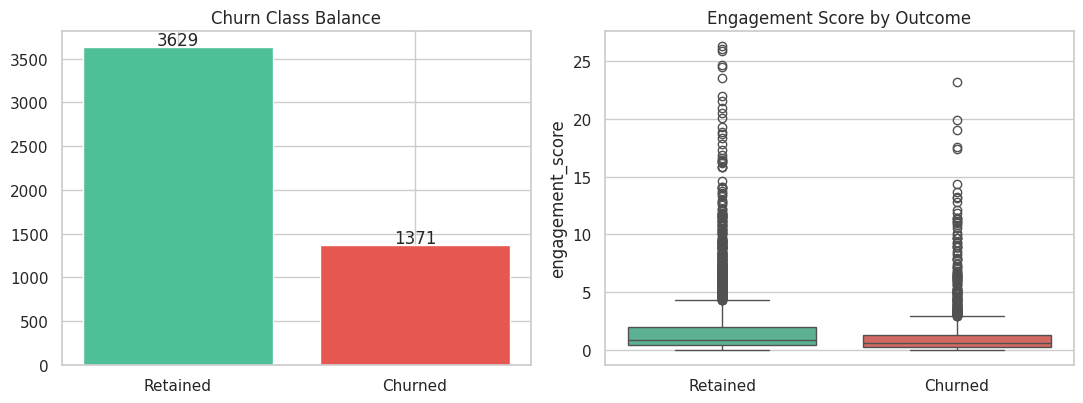

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4.2))

counts = processed_df["churned"].value_counts().sort_index()
axes[0].bar(["Retained", "Churned"], counts.values, color=["#4FBF97", "#E5574F"])
axes[0].set_title("Churn Class Balance")
for i, v in enumerate(counts.values):
    axes[0].text(i, v + 20, str(v), ha="center")

sns.boxplot(data=processed_df, x="churned", y="engagement_score", hue="churned",
            palette={0: "#4FBF97", 1: "#E5574F"}, legend=False, ax=axes[1])
axes[1].set_xticks([0, 1]); axes[1].set_xticklabels(["Retained", "Churned"])
axes[1].set_title("Engagement Score by Outcome"); axes[1].set_xlabel("")

fig.tight_layout()
plt.show()

Retained and churned customers look broadly similar on `engagement_score`
alone — most of the separating signal in this dataset comes from
`contract_type`, `tenure_months`, and `days_since_last_login` together
(see the permutation-importance results in `MODEL_CARD.md`), not from any
single engineered feature in isolation.

## 5. Train a model (processed -> a fitted pipeline)

In [6]:
model, metrics = train(processed_df)
metrics

{'model_type': 'StackingEnsemble',
 'roc_auc': 0.6269,
 'optimal_threshold': 0.2059,
 'precision_at_threshold': 0.3186,
 'recall_at_threshold': 0.8139,
 'f1_at_threshold': 0.4579,
 'accuracy_at_threshold': 0.472,
 'n_train': 4000,
 'n_test': 1000}

The `roc_auc` here should land close to the **0.627** reported for the v2
stacking ensemble in `MODEL_CARD.md` — small differences vs. that number
come from this module using fixed hyperparameters instead of the full
`RandomizedSearchCV` sweep in `model_training_v2.py`.

## 6. Score customers and bucket by risk

In [7]:
probabilities = predict_proba(model, processed_df)
bands = [risk_band(p, threshold=metrics["optimal_threshold"]) for p in probabilities]

risk_summary = pd.Series(bands).value_counts()
risk_summary

High        3393
Moderate    1274
Low          333
Name: count, dtype: int64

In [8]:
top10_idx = probabilities.argsort()[::-1][:10]
processed_df.iloc[top10_idx][
    ["age", "region", "plan_type", "contract_type", "tenure_months",
     "days_since_last_login", "support_tickets", "churned"]
].assign(churn_probability=probabilities[top10_idx].round(3))

,age,region,plan_type,contract_type,tenure_months,days_since_last_login,support_tickets,churned,churn_probability
740,34.0,Europe,Basic,Monthly,20,97,1,1,0.694
4259,29.0,Europe,Basic,Monthly,26,59,2,1,0.678
3254,52.0,North America,Basic,Monthly,4,38,2,1,0.673
3597,29.0,Europe,Basic,Monthly,6,59,0,1,0.663
4504,49.0,Asia-Pacific,Basic,Monthly,10,55,1,1,0.662
3955,45.0,Latin America,Basic,Monthly,10,51,1,1,0.660
334,35.0,Asia-Pacific,Basic,Monthly,4,46,0,1,0.657
1339,33.0,Latin America,Basic,Monthly,16,33,2,1,0.652
135,42.0,North America,Premium,Monthly,13,57,0,1,0.636
1628,51.0,Latin America,Standard,Monthly,12,75,0,1,0.636


## Where this fits in the rest of the project

- The tuned, fully-searched version of this same model lives in
  `Week3_ML_Model_Development/model_training_v2.py`, with its metrics
  recorded in `metrics_v2.json` and explained in `MODEL_CARD.md`.
- The live, clickable version of the model built here is the **Retention
  Console** — run `uvicorn api:app` from the project root and open
  `http://127.0.0.1:8000/`.
- Everything in this notebook is trained on **synthetic data only** — see
  the "Project Limitations" section of the main `README.md` before reading
  too much into any specific number above.